In [2]:
import hashlib
import os
import platform
import uuid
# 修改为自己的学号
STUDENT_ID = 20244080328
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV")
print(f"[Conda 环境] {CONDA_ENV}")
MACHINE_FP = hashlib.sha256(
 f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")

[Conda 环境] exp01
[学号] 20244080328
[机器指纹] 874abd1b1c3b7bdc
[RUN_ID] 20244080328-874abd1b1c3b7bdc


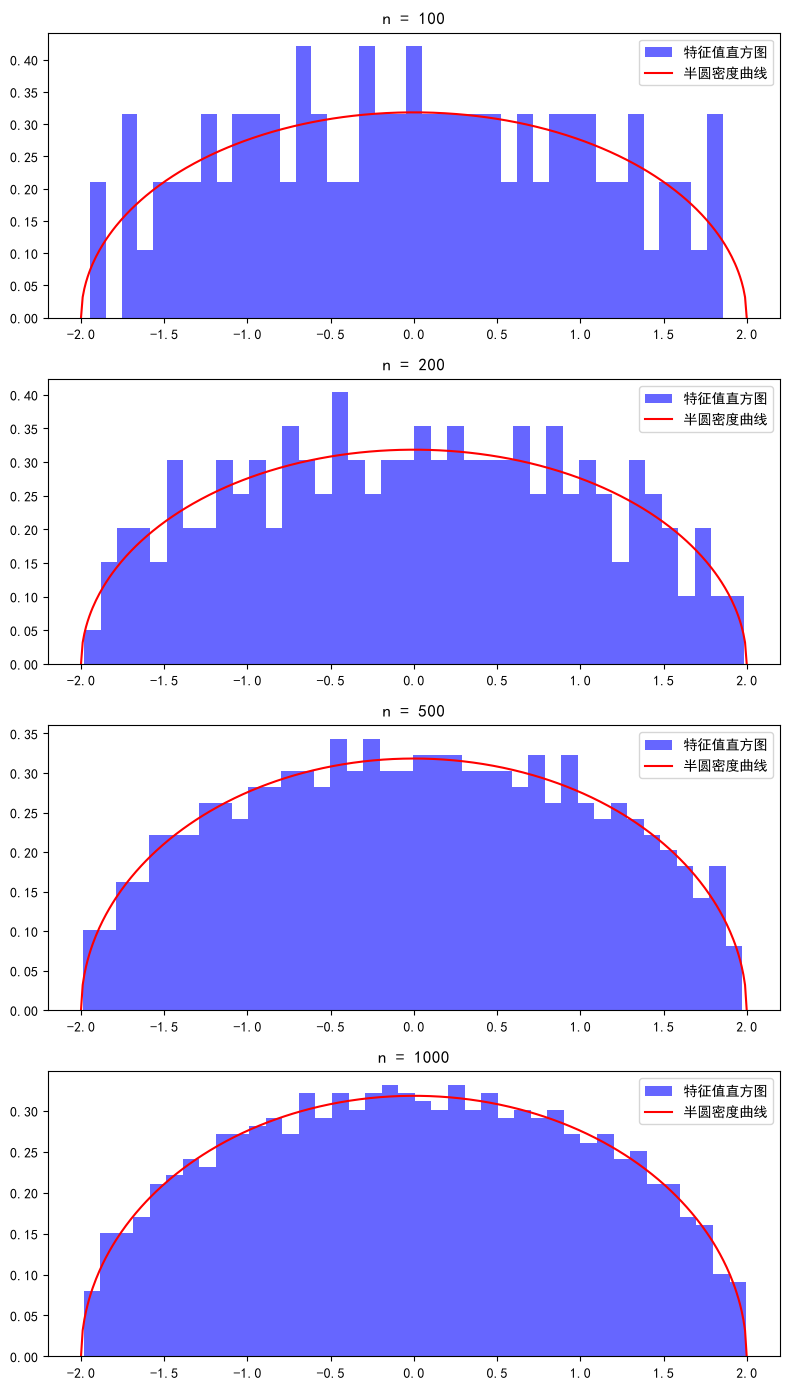

In [3]:
import numpy as np
import matplotlib.pyplot as plt


def wigner_density(x):
    x = np.asarray(x)
    result = np.zeros_like(x, dtype=float)
    mask = np.abs(x) <= 2
    result[mask] = np.sqrt(4 - x[mask] ** 2) / (2 * np.pi)
    return result


def generate_wigner(n):
    if not isinstance(n, (int, np.integer)) or n <= 0:
        raise ValueError("n 必须是正整数")
    a = np.random.normal(0, 1 / np.sqrt(n), size=(n, n))
    z = np.triu(a)
    z = z + z.T - np.diag(z.diagonal())
    return z


def get_spectrum(matrix):
    eig = np.linalg.eigvals(matrix)
    eig = eig.real[np.imag(eig) < 1e-10]
    return np.sort(eig)[::-1]


plt.rcParams["font.sans-serif"] = ["SimHei"]
plt.rcParams["axes.unicode_minus"] = False

ns = [100, 200, 500, 1000]
x = np.linspace(-2, 2, 400)

fig, axes = plt.subplots(4, 1, figsize=(8, 14))
for ax, n in zip(axes, ns):
    matrix = generate_wigner(n)
    spectrum = get_spectrum(matrix)
    ax.hist(spectrum, bins=40, density=True, color="blue", alpha=0.6, label="特征值直方图")
    ax.plot(x, wigner_density(x), color="red", label="半圆密度曲线")
    ax.set_title(f"n = {n}")
    ax.legend()

plt.tight_layout()
plt.show()


是否有效棋盘： True
初始棋盘：
[[0 1 0]
 [0 1 0]
 [1 1 0]]
下一步棋盘：
[[0 1 0]
 [0 1 0]
 [1 1 0]]
无效棋盘检查： False


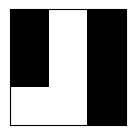

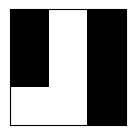

In [6]:
import numpy as np
import matplotlib.pyplot as plt


def is_valid_board(board):
    if not isinstance(board, np.ndarray) or board.ndim != 2:
        return False
    return np.all((board == 0) | (board == 1))


def gol_step(board):
    if not is_valid_board(board):
        raise ValueError("输入不是有效的生命游戏棋盘")
    neighbor = (
        np.roll(board, 1, axis=0) + np.roll(board, -1, axis=0)
        + np.roll(board, 1, axis=1) + np.roll(board, -1, axis=1)
        + np.roll(np.roll(board, 1, axis=0), 1, axis=1)
        + np.roll(np.roll(board, 1, axis=0), -1, axis=1)
        + np.roll(np.roll(board, -1, axis=0), 1, axis=1)
        + np.roll(np.roll(board, -1, axis=0), -1, axis=1)
    )
    next_board = np.zeros_like(board)
    next_board[(board == 1) & ((neighbor == 2) | (neighbor == 3))] = 1
    next_board[(board == 0) & (neighbor == 3)] = 1
    return next_board


def draw_gol_board(board):
    plt.figure(figsize=(board.shape[1] / 2, board.shape[0] / 2))
    plt.imshow(board, cmap=plt.get_cmap("gray"), vmin=0, vmax=1)
    plt.xticks([])
    plt.yticks([])
    plt.show()


board = np.array([
    [0, 1, 0],
    [0, 1, 0],
    [1, 1, 0],
])

print("是否有效棋盘：", is_valid_board(board))
print("初始棋盘：")
print(board)
next_board = gol_step(board)
print("下一步棋盘：")
print(next_board)
print("无效棋盘检查：", is_valid_board(np.array([[0, 1, 2]])))

draw_gol_board(board)
draw_gol_board(next_board)


In [7]:
import pandas as pd

df = pd.read_csv("iris.csv", index_col=0)

df.columns = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
df["species"] = ["setosa"] * 50 + ["versicolor"] * 50 + ["virginica"] * 50

print("数据点个数：", len(df))
print("各列数据类型：")
print(df.dtypes)
print("列名：", list(df.columns))
print("花卉种类：", df["species"].unique())
print()


df.loc[34] = [4.9, 3.1, 1.5, 0.2, "setosa"]
df.loc[37] = [4.9, 3.6, 1.4, 0.1, "setosa"]
print("修改后的第 35、38 行：")
print(df.loc[[34, 37]])
print()


df["Petal.Ratio"] = df["petal_length"] / df["petal_width"]
df["Sepal.Ratio"] = df["sepal_length"] / df["sepal_width"]

df.to_csv("iris_corrected.csv", index=False)

result = df.groupby("species")[["Petal.Ratio", "Sepal.Ratio"]].agg(["mean", "median", "min", "max", "std"])
print(result)


数据点个数： 150
各列数据类型：
sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
species             str
dtype: object
列名： ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']
花卉种类： <StringArray>
['setosa', 'versicolor', 'virginica']
Length: 3, dtype: str

修改后的第 35、38 行：
    sepal_length  sepal_width  petal_length  petal_width species
34           4.9          3.1           1.5          0.2  setosa
37           4.9          3.6           1.4          0.1  setosa

           Petal.Ratio                                     Sepal.Ratio  \
                  mean    median       min   max       std        mean   
species                                                                  
setosa        6.908000  7.000000  2.666667  15.0  2.854545    1.471380   
versicolor    3.182408  3.230769  0.335714   4.1  0.515861    2.165531   
virginica     2.780662  2.666667  2.125000   4.0  0.407367    2.230453   

                                